**Kaggle上预测房价的一个竞赛**

## 准备数据集的下载与导入内存

### 前置函数

In [28]:
import hashlib
import os
import tarfile
import zipfile
import requests

In [29]:
DATA_HUB = dict()
DATA_URL = 'http://d2l-data.s3-accelerate.amazonaws.com/'

In [30]:
#将数据下载下来，并返回文件名
def download(name, cache_dir=os.path.join('.', 'data')):  
    assert name in DATA_HUB, f"{name} 不存在于 {DATA_HUB}"
    url, sha1_hash = DATA_HUB[name]
    os.makedirs(cache_dir, exist_ok=True)
    fname = os.path.join(cache_dir, url.split('/')[-1])
    if os.path.exists(fname):
        sha1 = hashlib.sha1()
        with open(fname, 'rb') as f:
            while True:
                data = f.read(1048576)
                if not data:break
                sha1.update(data)
        if sha1.hexdigest() == sha1_hash:return fname  
    print(f'正在从{url}下载{fname}...')
    r = requests.get(url, stream=True, verify=True)
    with open(fname, 'wb') as f:f.write(r.content)
    return fname
#下载并解压
def download_extract(name, folder=None): 
    fname = download(name)
    base_dir = os.path.dirname(fname)
    data_dir, ext = os.path.splitext(fname)
    if ext == '.zip':fp = zipfile.ZipFile(fname, 'r')
    elif ext in ('.tar', '.gz'):fp = tarfile.open(fname, 'r')
    else:assert False, '只有zip/tar文件可以被解压缩'
    fp.extractall(base_dir)
    return os.path.join(base_dir, folder) if folder else data_dir
#缓存到目录中
def download_all():  
    for name in DATA_HUB:download(name)

In [31]:
%matplotlib inline
import numpy as np
import pandas as pd
import torch
from torch import nn
from d2l import torch as d2l

### 数据准备

#### 数据下载

In [32]:
DATA_HUB['kaggle_house_train'] = (  
    DATA_URL + 'kaggle_house_pred_train.csv',
    '585e9cc93e70b39160e7921475f9bcd7d31219ce')

DATA_HUB['kaggle_house_test'] = ( 
    DATA_URL + 'kaggle_house_pred_test.csv',
    'fa19780a7b011d9b009e8bff8e99922a8ee2eb90')

train_data = pd.read_csv(download('kaggle_house_train'))
test_data = pd.read_csv(download('kaggle_house_test'))

#### 数据预处理

In [33]:
#特征值的预处理
#对于训练集：把 ID 那一列拿掉，把最后一列的真实房价拿掉（只保留 features，不要 labels）
all_features = pd.concat((train_data.iloc[:, 1:-1], test_data.iloc[:, 1:]))
#寻找缺失的数据（na）
numeric_features = all_features.dtypes[all_features.dtypes != 'object'].index
#若测试数据缺失，则可根据训练数据计算均值和标准差
all_features[numeric_features] = all_features[numeric_features].apply(lambda x: (x - x.mean()) / (x.std()))
#在标准化数据之后，所有均值消失，因此我们可以将缺失值设置为0
all_features[numeric_features] = all_features[numeric_features].fillna(0)
# Dummy_na=True 将 na（缺失值）视为有效的特征值，并为其创建指示符特征
all_features = pd.get_dummies(all_features, dummy_na=True)

In [34]:
#获取特征和标签
n_train = train_data.shape[0]
all_features = pd.get_dummies(all_features, dummy_na=True)
train_features = torch.tensor(all_features[:n_train].values.astype(np.float32), dtype=torch.float32)
test_features = torch.tensor(all_features[n_train:].values.astype(np.float32), dtype=torch.float32)
train_labels = torch.tensor(train_data.SalePrice.values.reshape(-1, 1), dtype=torch.float32)

# 配置模型

In [35]:
loss = nn.MSELoss()
in_features = train_features.shape[1]

def get_net():
    net = nn.Sequential(nn.Linear(in_features,128),
                        nn.ReLU(),
                        nn.Linear(128, 32),
                        nn.ReLU(),
                        nn.Linear(32, 1)
                        )
    return net

In [36]:
#为了在取对数时进一步稳定该值，将小于 1 的值设置为 1
#这里通过取对数将房价金额变换为对数，避免了金额相差过大对训练的影响
def log_rmse(net, features, labels):
    clipped_preds = torch.clamp(net(features), 1, float('inf'))
    rmse = torch.sqrt(loss(torch.log(clipped_preds), torch.log(labels)))
    return rmse.item()

In [37]:
#训练循环
def train(net, train_features, train_labels, test_features, test_labels,
          num_epochs, learning_rate, weight_decay, batch_size):
    train_ls, test_ls = [], []
    train_iter = d2l.load_array((train_features, train_labels), batch_size)
    #这里使用的是Adam优化算法
    optimizer = torch.optim.Adam(net.parameters(),
                                 lr = learning_rate,
                                 weight_decay = weight_decay)
    for epoch in range(num_epochs):
        for X, y in train_iter:
            optimizer.zero_grad()
            l = loss(net(X), y)
            l.backward()
            optimizer.step()
        train_ls.append(log_rmse(net, train_features, train_labels))
        if test_labels is not None:
            test_ls.append(log_rmse(net, test_features, test_labels))
    return train_ls, test_ls

## K 折交叉验证

In [38]:
#定义一个函数，返回 K 折交叉验证下的第 i 折验证数据和其余的训练数据
def get_k_fold_data(k, i, X, y):
    assert k > 1
    fold_size = X.shape[0] // k
    X_train, y_train = None, None
    for j in range(k):
        idx = slice(j * fold_size, (j + 1) * fold_size)
        X_part, y_part = X[idx, :], y[idx]
        if j == i:
            X_valid, y_valid = X_part, y_part
        elif X_train is None:
            X_train, y_train = X_part, y_part
        else:
            X_train = torch.cat([X_train, X_part], 0)
            y_train = torch.cat([y_train, y_part], 0)
    return X_train, y_train, X_valid, y_valid

In [39]:
#在训练后返回训练误差
def k_fold(k, X_train, y_train, num_epochs, learning_rate, weight_decay, batch_size):
    train_l_sum, valid_l_sum = 0, 0
    for i in range(k):
        data = get_k_fold_data(k, i, X_train, y_train)
        net = get_net()
        train_ls, valid_ls = train(net, *data, num_epochs, learning_rate,
                                   weight_decay, batch_size)
        train_l_sum += train_ls[-1]
        valid_l_sum += valid_ls[-1]
        if i == 0:
            d2l.plot(list(range(1, num_epochs + 1)), [train_ls, valid_ls],
                     xlabel='epoch', ylabel='rmse', xlim=[1, num_epochs],
                     legend=['train', 'valid'], yscale='log')
        print(f"折{i + 1}, 训练log rmse: {float(train_ls[-1]):f}, "
              f"验证log rmse: {float(valid_ls[-1]):f}")
    return train_l_sum / k, valid_l_sum / k

折1, 训练log rmse: 0.060819, 验证log rmse: 0.143733
折2, 训练log rmse: 0.055934, 验证log rmse: 0.166645
折3, 训练log rmse: 0.063507, 验证log rmse: 0.153614
折4, 训练log rmse: 0.055321, 验证log rmse: 0.123651
折5, 训练log rmse: 0.048123, 验证log rmse: 0.162157
5-折验证: 平均训练log rmse: 0.056741, 平均验证log rmse: 0.149960


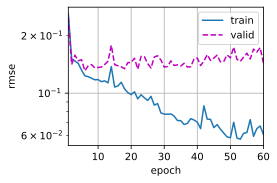

In [40]:
#超参数
k = 5
num_epochs = 60
lr = 0.13
weight_decay = 0.011
batch_size = 64

#K 折交叉验证的训练
train_l, valid_l = k_fold(k, train_features, train_labels, num_epochs, lr, weight_decay, batch_size)
print(f'{k}-折验证: 平均训练log rmse: {float(train_l):f}, '
      f'平均验证log rmse: {float(valid_l):f}')

## 训练并预测

In [ ]:
def train_and_pred(train_features, test_features, train_labels, test_data,
                   num_epochs, lr, weight_decay, batch_size):
    net = get_net()
    train_ls, _ = train(net, train_features, train_labels, None, None,
                        num_epochs, lr, weight_decay, batch_size)
    d2l.plot(np.arange(1, num_epochs + 1), [train_ls], xlabel='epoch',
             ylabel='log rmse', xlim=[1, num_epochs], yscale='log')
    print(f'训练log rmse: {float(train_ls[-1]):f}')
    # 将网络应用于测试集。
    preds = net(test_features).detach().numpy()
    # 将其重新格式化以导出到Kaggle
    test_data['SalePrice'] = pd.Series(preds.reshape(1, -1)[0])
    submission = pd.concat([test_data['Id'], test_data['SalePrice']], axis=1)
    submission.to_csv('submission.csv', index=False)

训练log rmse: 0.124865


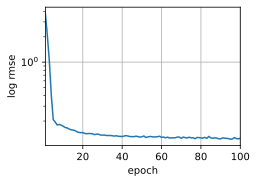

In [ ]:
train_and_pred(train_features, test_features, train_labels, test_data, num_epochs, lr, weight_decay, batch_size)